<a href="https://colab.research.google.com/github/2025ciayushraj/DAV-/blob/main/outlier_regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Original Dataset:


,Student,Marks
0,A,45
1,B,50
2,C,52
3,D,48
4,E,55
5,F,60
6,G,58
7,H,62
8,I,65
9,J,59


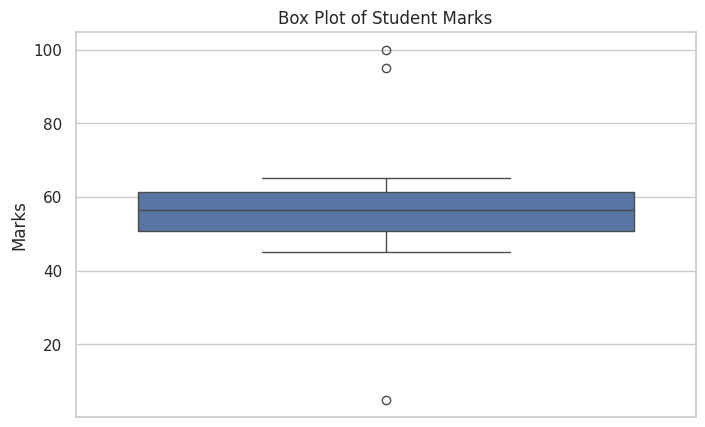

Q1 = 50.75
Q3 = 61.25
IQR = 10.5
Lower Limit = 35.0
Upper Limit = 77.0

Outliers detected using IQR:


,Student,Marks
17,R,95
18,S,100
19,T,5


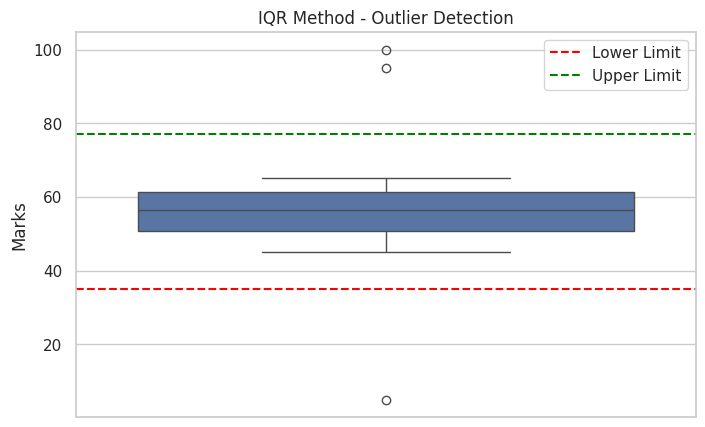

Marks before and after IQR capping:


,Student,Marks,Marks_IQR_Capped
0,A,45,45
1,B,50,50
2,C,52,52
3,D,48,48
4,E,55,55
5,F,60,60
6,G,58,58
7,H,62,62
8,I,65,65
9,J,59,59


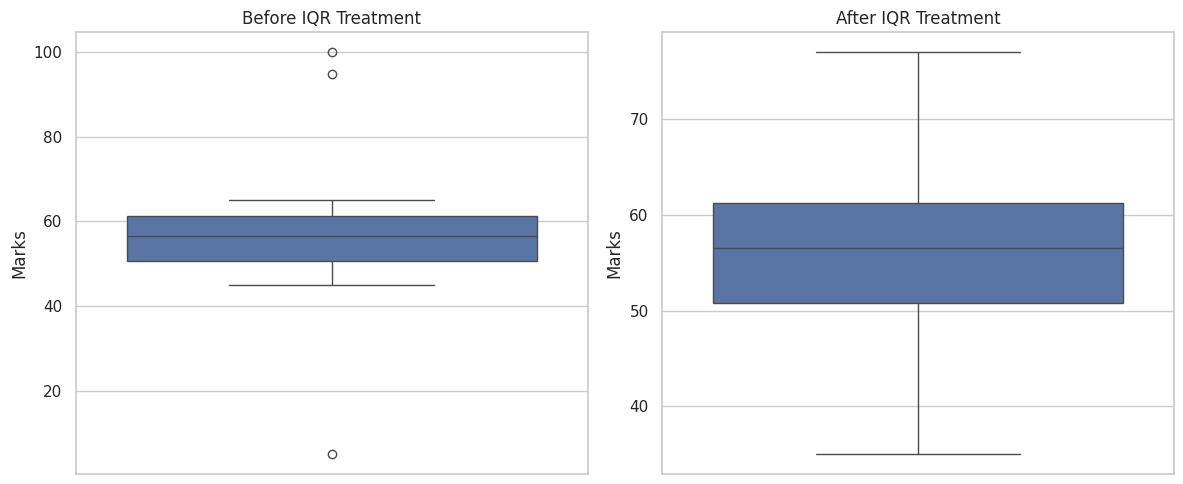

Marks and their Z-scores:


,Student,Marks,Z_score
0,A,45,-0.676200
1,B,50,-0.400200
2,C,52,-0.289800
3,D,48,-0.510600
4,E,55,-0.124200
5,F,60,0.151800
6,G,58,0.041400
7,H,62,0.262200
8,I,65,0.427800
9,J,59,0.096600


Outliers detected using Z-score:


,Student,Marks,Marks_IQR_Capped,Z_score,Z_Outlier


All observations with their outlier status:


,Student,Marks,Z_score,Z_Outlier
0,A,45,-0.676200,False
1,B,50,-0.400200,False
2,C,52,-0.289800,False
3,D,48,-0.510600,False
4,E,55,-0.124200,False
5,F,60,0.151800,False
6,G,58,0.041400,False
7,H,62,0.262200,False
8,I,65,0.427800,False
9,J,59,0.096600,False


Mean = 57.25
Standard Deviation = 18.586568438412442
Lower Z-score limit = 1.4902946847626737
Upper Z-score limit = 113.00970531523733
Marks before and after Z-score capping:


,Student,Marks,Marks_Z_Capped
0,A,45,45
1,B,50,50
2,C,52,52
3,D,48,48
4,E,55,55
5,F,60,60
6,G,58,58
7,H,62,62
8,I,65,65
9,J,59,59


Comparison of original and treated marks:


,Student,Marks,Marks_IQR_Capped,Marks_Z_Capped
0,A,45,45,45
1,B,50,50,50
2,C,52,52,52
3,D,48,48,48
4,E,55,55,55
5,F,60,60,60
6,G,58,58,58
7,H,62,62,62
8,I,65,65,65
9,J,59,59,59


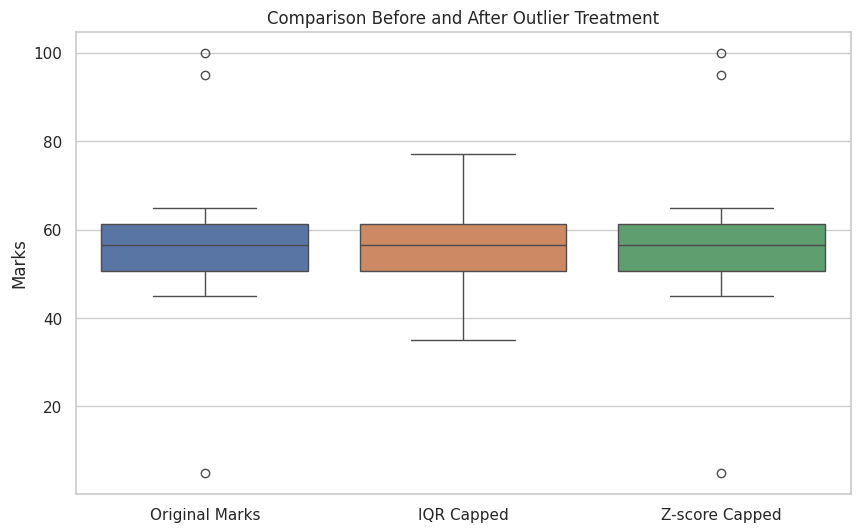

Total number of observations: 20
Number of IQR outliers: 3
Number of Z-score outliers: 0

Final Dataset:


,Student,Marks,Marks_IQR_Capped,Z_score,Z_Outlier,Marks_Z_Capped
0,A,45,45,-0.676200,False,45
1,B,50,50,-0.400200,False,50
2,C,52,52,-0.289800,False,52
3,D,48,48,-0.510600,False,48
4,E,55,55,-0.124200,False,55
5,F,60,60,0.151800,False,60
6,G,58,58,0.041400,False,58
7,H,62,62,0.262200,False,62
8,I,65,65,0.427800,False,65
9,J,59,59,0.096600,False,59


In [1]:

# ============================================================
# OUTLIER DETECTION AND TREATMENT USING IQR AND Z-SCORE
# ============================================================

# 1. Import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid")


# 2. Create a sample dataset
data = {
    'Student': [
        'A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'J',
        'K', 'L', 'M', 'N', 'O', 'P', 'Q', 'R', 'S', 'T'
    ],
    'Marks': [
        45, 50, 52, 48, 55, 60, 58, 62, 65, 59,
        61, 57, 63, 56, 54, 51, 49, 95, 100, 5
    ]
}

df = pd.DataFrame(data)

print("Original Dataset:")
display(df)


# 3. Visualize the data using a box plot
plt.figure(figsize=(8, 5))
sns.boxplot(y=df['Marks'])
plt.title("Box Plot of Student Marks")
plt.ylabel("Marks")
plt.show()


# ============================================================
# 4. DETECT OUTLIERS USING IQR
# ============================================================

# Step 1: Calculate Q1 and Q3
Q1 = df['Marks'].quantile(0.25)
Q3 = df['Marks'].quantile(0.75)

print("Q1 =", Q1)
print("Q3 =", Q3)

# Step 2: Calculate IQR
IQR = Q3 - Q1
print("IQR =", IQR)

# Step 3: Calculate lower and upper limits
lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

print("Lower Limit =", lower_limit)
print("Upper Limit =", upper_limit)

# Step 4: Identify outliers
outliers_iqr = df[
    (df['Marks'] < lower_limit) |
    (df['Marks'] > upper_limit)
]

print("\nOutliers detected using IQR:")
display(outliers_iqr)


# 5. Visualize IQR outliers
plt.figure(figsize=(8, 5))
sns.boxplot(y=df['Marks'])

plt.axhline(
    lower_limit, color='red', linestyle='--',
    label='Lower Limit'
)
plt.axhline(
    upper_limit, color='green', linestyle='--',
    label='Upper Limit'
)

plt.title("IQR Method - Outlier Detection")
plt.ylabel("Marks")
plt.legend()
plt.show()


# ============================================================
# 6. IQR OUTLIER TREATMENT - CAPPING
# ============================================================

df['Marks_IQR_Capped'] = df['Marks'].clip(
    lower=lower_limit,
    upper=upper_limit
)

print("Marks before and after IQR capping:")
display(df[['Student', 'Marks', 'Marks_IQR_Capped']])


# 7. Visualize before and after IQR treatment
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.boxplot(y=df['Marks'], ax=axes[0])
axes[0].set_title("Before IQR Treatment")
axes[0].set_ylabel("Marks")

sns.boxplot(y=df['Marks_IQR_Capped'], ax=axes[1])
axes[1].set_title("After IQR Treatment")
axes[1].set_ylabel("Marks")

plt.tight_layout()
plt.show()


# ============================================================
# 8. DETECT OUTLIERS USING Z-SCORE
# ============================================================

# Calculate Z-scores
df['Z_score'] = stats.zscore(df['Marks'])

print("Marks and their Z-scores:")
display(df[['Student', 'Marks', 'Z_score']])

# ============================================================
# 9. IDENTIFY Z-SCORE OUTLIERS
# ============================================================

# Common rule: absolute Z-score greater than 3
df['Z_Outlier'] = abs(df['Z_score']) > 3

z_outliers = df[df['Z_Outlier']]

print("Outliers detected using Z-score:")
display(z_outliers)

print("All observations with their outlier status:")
display(df[['Student', 'Marks', 'Z_score', 'Z_Outlier']])


# ============================================================
# 10. Z-SCORE OUTLIER TREATMENT - CAPPING
# ============================================================

mean = df['Marks'].mean()
std = df['Marks'].std()

lower_z_limit = mean - 3 * std
upper_z_limit = mean + 3 * std

print("Mean =", mean)
print("Standard Deviation =", std)
print("Lower Z-score limit =", lower_z_limit)
print("Upper Z-score limit =", upper_z_limit)

# Cap values at the Z-score boundaries
df['Marks_Z_Capped'] = df['Marks'].clip(
    lower=lower_z_limit,
    upper=upper_z_limit
)

print("Marks before and after Z-score capping:")
display(df[['Student', 'Marks', 'Marks_Z_Capped']])


# ============================================================
# 11. COMPARE THE THREE VERSIONS
# ============================================================

print("Comparison of original and treated marks:")
display(
    df[
        ['Student', 'Marks',
         'Marks_IQR_Capped', 'Marks_Z_Capped']
    ]
)

# Visualize the comparison
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df[
        ['Marks', 'Marks_IQR_Capped', 'Marks_Z_Capped']
    ]
)

plt.title("Comparison Before and After Outlier Treatment")
plt.ylabel("Marks")
plt.xticks(
    ticks=[0, 1, 2],
    labels=['Original Marks', 'IQR Capped', 'Z-score Capped']
)
plt.show()


# ============================================================
# 12. FINAL SUMMARY
# ============================================================

print("Total number of observations:", len(df))
print("Number of IQR outliers:", len(outliers_iqr))
print("Number of Z-score outliers:", len(z_outliers))

print("\nFinal Dataset:")
display(df)
